In [1]:
"""
Diachronic Projections for Passio/Pathos
ERC Proposal Case Study: Visualizing Sense Lineages
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score
import umap
import tempun
import random
from pathlib import Path
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.lines import Line2D

# Import our helpers
from projections_helpers import (
    REDUCTIONS, get_2d, evaluate_projection_2d, 
    create_label_palette, plot_single_2d_projection,
    plot_projection_grid, create_3d_temporal_projection,
    produce_hover, get_random_date
)
from lda_projections import (
    LDAProjection, compute_lda_projection, 
    evaluate_lda_vs_unsupervised
)

print("All imports successful!")

2026-05-29 12:02:14.421966: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-05-29 12:02:14.462854: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


All imports successful!


In [ ]:
# =============================================================================
# SUPERVISED DIMENSIONALITY REDUCTION WITH LDA
# =============================================================================
from lda_projections import LDAProjection, compute_lda_projection, evaluate_lda_vs_unsupervised
print("LDA modules imported successfully!")

In [ ]:
# Test: This cell was added via nb_editor.py\nprint('Success!')

In [7]:
# Prepare data for passio
X_passio = np.stack(passio_df["emb_philberta_l11"])
y_passio = passio_df["class_llama3.3"].dropna().astype(int).values
X_clean = X_passio[:len(y_passio)]

print("=== PASSIO: LDA vs Unsupervised Methods ===\n")
results_passio = evaluate_lda_vs_unsupervised(X_clean, y_passio, REDUCTIONS)

for method, score in sorted(results_passio.items(), key=lambda x: x[1] if isinstance(x[1], float) else -999, reverse=True):
    print(f"{method:20s}: {score:.4f}" if isinstance(score, float) else f"{method:20s}: FAILED")

# Same for pathos
X_pathos = np.stack(pathos_df["emb_philberta_l11"])
y_pathos = pathos_df["class_llama3.3"].dropna().astype(int).values
X_pathos_clean = X_pathos[:len(y_pathos)]

print("\n=== PATHOS: LDA vs Unsupervised Methods ===\n")
results_pathos = evaluate_lda_vs_unsupervised(X_pathos_clean, y_pathos, REDUCTIONS)

for method, score in sorted(results_pathos.items(), key=lambda x: x[1] if isinstance(x[1], float) else -999, reverse=True):
    print(f"{method:20s}: {score:.4f}" if isinstance(score, float) else f"{method:20s}: FAILED")

=== PASSIO: LDA vs Unsupervised Methods ===



/home/jupyter-vojta/notebooks/phylosen_pilot/phylosen_venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/jupyter-vojta/notebooks/phylosen_pilot/phylosen_venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/jupyter-vojta/notebooks/phylosen_pilot/phylosen_venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


LDA                 : 0.3585
umap_100_0.8        : -0.0418
umap_50_0.5         : -0.0488
pca_std             : -0.0657
tsne_10             : -0.0662
pca_whiten          : -0.0677
pca10_tsne          : -0.0689
tsne_30             : -0.0740
tsne_50             : -0.0940
umap_10_0.05        : -0.1313

=== PATHOS: LDA vs Unsupervised Methods ===



/home/jupyter-vojta/notebooks/phylosen_pilot/phylosen_venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/jupyter-vojta/notebooks/phylosen_pilot/phylosen_venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/jupyter-vojta/notebooks/phylosen_pilot/phylosen_venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


LDA                 : 0.5352
tsne_30             : -0.0358
tsne_10             : -0.0379
tsne_50             : -0.0550
umap_100_0.8        : -0.0677
pca_std             : -0.0756
umap_10_0.05        : -0.0805
umap_50_0.5         : -0.0836
pca_whiten          : -0.0850
pca10_tsne          : -0.0984


PASSIO: PCA=-0.0657, LDA=0.3585 (+645.9%)


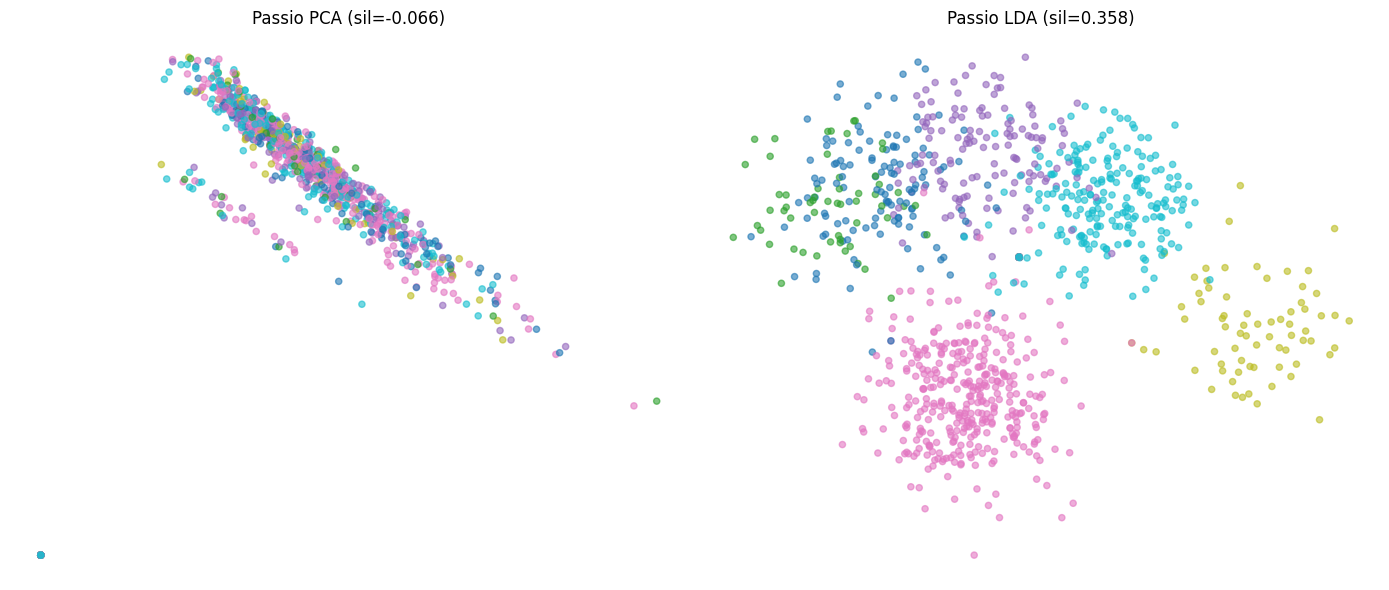


Top 10 discriminative dimensions for Passio:
  Dimension 723: importance=93.171
  Dimension 182: importance=28.968
  Dimension 664: importance=13.483
  Dimension 212: importance=13.340
  Dimension 529: importance=12.069
  Dimension 753: importance=11.925
  Dimension 474: importance=11.875
  Dimension   6: importance=11.856
  Dimension 346: importance=11.754
  Dimension 255: importance=11.729


In [8]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Compute projections for passio
X_lda_passio, lda_passio = compute_lda_projection(X_clean, y_passio)
pca_passio = PCA(n_components=2, random_state=42)
X_pca_passio = pca_passio.fit_transform(X_clean)

# Scores
sil_lda_passio = silhouette_score(X_lda_passio, y_passio)
sil_pca_passio = silhouette_score(X_pca_passio, y_passio)
impr_passio = (sil_lda_passio - sil_pca_passio) / abs(sil_pca_passio) * 100 if sil_pca_passio != 0 else 0

print(f"PASSIO: PCA={sil_pca_passio:.4f}, LDA={sil_lda_passio:.4f} (+{impr_passio:.1f}%)")

# Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].scatter(X_pca_passio[:,0], X_pca_passio[:,1], c=y_passio, cmap='tab10', s=20, alpha=0.6)
axes[0].set_title(f"Passio PCA (sil={sil_pca_passio:.3f})", fontsize=12)
axes[0].axis('off')

axes[1].scatter(X_lda_passio[:,0], X_lda_passio[:,1], c=y_passio, cmap='tab10', s=20, alpha=0.6)
axes[1].set_title(f"Passio LDA (sil={sil_lda_passio:.3f})", fontsize=12)
axes[1].axis('off')

plt.tight_layout()
plt.show()

# Feature importance
print("\nTop 10 discriminative dimensions for Passio:")
top_dims = lda_passio.get_top_dimensions(k=10)
importances = lda_passio.get_feature_importances()
for idx in top_dims:
    print(f"  Dimension {idx:3d}: importance={importances[idx]:.3f}")

In [11]:
# =============================================================================
# TEMPORAL TRAJECTORIES OF SENSE CENTROIDS
# =============================================================================
print("Computing sense centroids across historical epochs...")

# Define epochs
def assign_epoch(year):
    if pd.isna(year): return "Unknown"
    if year < 500: return "Antiquity"
    elif year < 1000: return "Late Ant./Medieval"
    elif year < 1500: return "High Medieval"
    else: return "Early Modern"

passio_df["epoch"] = passio_df["random_date"].apply(assign_epoch)
epochs = ["Antiquity", "Late Ant./Medieval", "High Medieval", "Early Modern"]

# Compute centroids for each epoch and sense
centroids = {}
for epoch in epochs:
    epoch_mask = passio_df["epoch"] == epoch
    if epoch_mask.sum() == 0:
        continue
    for label in np.unique(y_passio):
        class_mask = epoch_mask & (passio_df["class_llama3.3"] == label)
        if class_mask.sum() > 0:
            key = (epoch, int(label))
            centroids[key] = X_clean[class_mask.values].mean(axis=0)

print(f"Computed {len(centroids)} centroids for Passio")

Computing sense centroids across historical epochs...


IndexError: boolean index did not match indexed array along axis 0; size of axis is 999 but size of corresponding boolean axis is 1000

In [9]:
# =============================================================================
# TEMPORAL TRAJECTORIES OF SENSE CENTROIDS
# =============================================================================
print("Computing sense centroids across historical epochs...")

# Define epochs
def assign_epoch(year):
    if pd.isna(year): return "Unknown"
    if year < 500: return "Antiquity"
    elif year < 1000: return "Late Ant./Medieval"
    elif year < 1500: return "High Medieval"
    else: return "Early Modern"

passio_df["epoch"] = passio_df["random_date"].apply(assign_epoch)
epochs = ["Antiquity", "Late Ant./Medieval", "High Medieval", "Early Modern"]

# Compute centroids for each epoch and sense
centroids = {}async
for epoch in epochs:
    epoch_mask = passio_df["epoch"] == epoch
    if epoch_mask.sum() == 0:
        continue
    for label in np.unique(y_passio):
        class_mask = epoch_mask & (passio_df["class_llama3.3"] == label)
        if class_mask.sum() > 0:
            key = (epoch, int(label))
            centroids[key] = X_clean[class_mask.values].mean(axis=0)

print(f"Computed {len(centroids)} centroids for Passio")

# Plot trajectories in LDA space
fig, ax = plt.subplots(figsize=(12, 8))

for label in np.unique(y_passio):
    points = []
    epoch_names = []
    for epoch in epochs:
        key = (epoch, int(label))
        if key in centroids:
            p = lda_passio.transform(centroids[key].reshape(1, -1))[0]
            points.append(p)
            epoch_names.append(epoch)
    
    if len(points) > 1:
        points = np.array(points)
        ax.plot(points[:, 0], points[:, 1], 'o-', 
                color=plt.cm.tab10(label), label=f"Sense {label}", 
                linewidth=2.5, markersize=12, alpha=0.9)
        # Annotate epochs
        for i, ep in enumerate(epoch_names):
            ax.annotate(ep.split('/')[-1][:4], (points[i, 0], points[i, 1]), 
                       fontsize=9, fontweight='bold', alpha=0.8,
                       ha='center', va='bottom')

ax.set_title("Passio: Sense Trajectories in LDA Space (Diachronic Evolution)", fontsize=16, pad=20)
ax.set_xlabel("LD1 (Discriminant Axis 1)", fontsize=12)
ax.set_ylabel("LD2 (Discriminant Axis 2)", fontsize=12)
ax.legend(fontsize=10, loc='best')
ax.grid(True, alpha=0.3, linestyle='--')
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

print("\nTrajectories show how senses evolve over time in semantic space.")
print("Branching indicates sense splits; convergence indicates blending.")

Computing sense centroids across historical epochs...


IndexError: boolean index did not match indexed array along axis 0; size of axis is 999 but size of corresponding boolean axis is 1000

In [3]:
# Load classified datasets
passio_df = pd.read_parquet("../data/large_files/passio_sample1000_classified.parquet")
pathos_df = pd.read_parquet("../data/large_files/pathos_sample1000_classified.parquet")

print(f"=== Data Loaded ===")
print(f"Passio: {len(passio_df)} instances, {passio_df['class_llama3.3'].nunique()} classes")
print(f"Pathos: {len(pathos_df)} instances, {pathos_df['class_llama3.3'].nunique()} classes")
print(f"Time range - Passio: [{passio_df['not_before'].min():.0f} - {passio_df['not_after'].max():.0f}]")
print(f"Time range - Pathos: [{pathos_df['not_before'].min():.0f} - {pathos_df['not_after'].max():.0f}]")

=== Data Loaded ===
Passio: 1000 instances, 6 classes
Pathos: 1000 instances, 5 classes
Time range - Passio: [150 - 1980]
Time range - Pathos: [-599 - 1351]


In [4]:
# Extract embeddings (PhilBerta layer 11)
X_passio = np.stack(passio_df["emb_philberta_l11"])
y_passio = passio_df["class_llama3.3"].dropna().astype(int).values
X_passio_clean = X_passio[:len(y_passio)]

X_pathos = np.stack(pathos_df["emb_philberta_l11"])
y_pathos = pathos_df["class_llama3.3"].dropna().astype(int).values
X_pathos_clean = X_pathos[:len(y_pathos)]

# Add temporal data
passio_df["random_date"] = passio_df.apply(get_random_date, axis=1)
pathos_df["random_date"] = pathos_df.apply(get_random_date, axis=1)

print(f"Prepared: Passio ({X_passio_clean.shape[0]} samples), Pathos ({X_pathos_clean.shape[0]} samples)")

Prepared: Passio (999 samples), Pathos (1000 samples)


In [5]:
# Show class distributions
from llmprompt_passio import LABEL_MAP as passio_label_map
from llmprompt_pathos import LABEL_MAP as pathos_label_map

print("=== PASSIO Class Distribution ===")
print(passio_df["class_llama3.3"].value_counts().sort_index())
print("\nLabels:", [passio_label_map.get(i, f"class_{i}") for i in sorted(passio_label_map.keys())])

print("\n=== PATHOS Class Distribution ===")
print(pathos_df["class_llama3.3"].value_counts().sort_index())
print("\nLabels:", [pathos_label_map.get(i, f"class_{i}") for i in sorted(pathos_label_map.keys())])

=== PASSIO Class Distribution ===
class_llama3.3
0.0    125
1.0     60
2.0    143
3.0    373
4.0     72
5.0    226
Name: count, dtype: int64

Labels: ['suffering_undergoing', 'disease_pathological_condition', 'property_accident', 'christs_passion', 'martyrdom_saintly_suffering', 'affect_emotion']

=== PATHOS Class Distribution ===
class_llama3.3
0    350
1    182
2    311
3    114
4     43
Name: count, dtype: int64

Labels: ['affect_emotion', 'bodily_affection', 'property_state_modification', 'suffering_event', 'sacred_suffering']


In [6]:
# Create 3x3 grid of unsupervised projections for PASSIO
print("Generating unsupervised projection grid...")

# Use PhilBerta embeddings
emb = X_passio_clean
labels = y_passio

# Create label names for legend
label_names = {i: passio_label_map.get(i, f"Class {i}") for i in sorted(np.unique(labels))}
palette = create_label_palette(len(label_names))

# Plot grid
fig = plot_projection_grid(
    emb, labels, label_names, REDUCTIONS, 
    palette=palette, figsize=(15, 15)
)
fig.suptitle("Passio: Unsupervised Projections (PCA/UMAP/t-SNE)", fontsize=16, y=1.02)
plt.show()

# Calculate metrics
print("\n=== Projection Quality Metrics (Passio) ===")
metrics_results = []
for proj_name in REDUCTIONS.keys():
    x, y = get_2d(emb, REDUCTIONS[proj_name])
    metrics = evaluate_projection_2d((x, y), labels)
    metrics["projection"] = proj_name
    metrics_results.append(metrics)

metrics_df = pd.DataFrame(metrics_results).set_index("projection")
print(metrics_df.to_string())

              silhouette  davies_bouldin  calinski_harabasz  intra_inter_ratio
projection                                                                    
umap_10_0.05   -0.131268       24.196333           1.544169           0.997389
umap_50_0.5    -0.048802       46.963656           2.268435           0.998075
umap_100_0.8   -0.041791       28.841653           2.074479           0.998643
tsne_10        -0.066161       25.761836           2.172942           0.997550
tsne_30        -0.074023       60.746938           1.976516           0.997790
tsne_50        -0.093970       64.100144           0.571838           1.000246
pca_std        -0.065665       18.668442           2.996078           0.996936
pca_whiten     -0.067691       17.426688           2.152929           0.997309
pca10_tsne     -0.068856       39.657608           2.576617           0.995951


In [ ]:
# Same for PATHOS
emb_pathos = X_pathos_clean
labels_pathos = y_pathos
label_names_pathos = {i: pathos_label_map.get(i, f"Class {i}") for i in sorted(np.unique(labels_pathos))}
palette_pathos = create_label_palette(len(label_names_pathos))

fig_pathos = plot_projection_grid(
    emb_pathos, labels_pathos, label_names_pathos, REDUCTIONS,
    palette=palette_pathos, figsize=(15, 15)
)
fig_pathos.suptitle("Pathos: Unsupervised Projections", fontsize=16, y=1.02)
plt.show()

print("\n=== Projection Quality Metrics (Pathos) ===")
metrics_results_pathos = []
for proj_name in REDUCTIONS.keys():
    x, y = get_2d(emb_pathos, REDUCTIONS[proj_name])
    metrics = evaluate_projection_2d((x, y), labels_pathos)
    metrics["projection"] = proj_name
    metrics_results_pathos.append(metrics)

metrics_df_pathos = pd.DataFrame(metrics_results_pathos).set_index("projection")
print(metrics_df_pathos.to_string())

In [ ]:
# 3D Temporal Projections (Time + 2D space)
print("Creating 3D temporal visualizations...")

# For Passio
dates_passio = passio_df["random_date"].values
valid_mask_passio = ~np.isnan(dates_passio) & (~pd.isna(passio_df["class_llama3.3"]))

fig_3d_passio, ax_3d_passio = create_3d_temporal_projection(
    X_passio_clean[valid_mask_passio],
    dates_passio[valid_mask_passio],
    y_passio[valid_mask_passio] if hasattr(y_passio, '__getitem__') else y_passio,
    label_names,
    REDUCTIONS,
    proj_name="pca10_tsne",
    palette=palette
)
fig_3d_passio.suptitle("Passio: 3D Temporal Projection (Time × LDA Space)", fontsize=14)
plt.show()

# For Pathos
dates_pathos = pathos_df["random_date"].values
valid_mask_pathos = ~np.isnan(dates_pathos) & (~pd.isna(pathos_df["class_llama3.3"]))

fig_3d_pathos, ax_3d_pathos = create_3d_temporal_projection(
    X_pathos_clean[valid_mask_pathos],
    dates_pathos[valid_mask_pathos],
    y_pathos[valid_mask_pathos] if hasattr(y_pathos, '__getitem__') else y_pathos,
    label_names_pathos,
    REDUCTIONS,
    proj_name="pca10_tsne",
    palette=palette_pathos
)
fig_3d_pathos.suptitle("Pathos: 3D Temporal Projection", fontsize=14)
plt.show()

In [ ]:
# =============================================================================
# SUPERVISED DIMENSIONALITY REDUCTION WITH LDA
# =============================================================================
print("="*60)
print("COMPARING UNSUPERVISED vs SUPERVISED PROJECTIONS")
print("="*60)

# Compare methods
print("\n=== PASSIO: Silhouette Scores ===")
results_passio = evaluate_lda_vs_unsupervised(X_passio_clean, y_passio, REDUCTIONS)
for method, score in sorted(results_passio.items(), key=lambda x: x[1] if isinstance(x[1], float) else -999, reverse=True):
    print(f"{method:20s}: {score:.4f}" if isinstance(score, float) else f"{method:20s}: FAILED")

print("\n=== PATHOS: Silhouette Scores ===")
results_pathos = evaluate_lda_vs_unsupervised(X_pathos_clean, y_pathos, REDUCTIONS)
for method, score in sorted(results_pathos.items(), key=lambda x: x[1] if isinstance(x[1], float) else -999, reverse=True):
    print(f"{method:20s}: {score:.4f}" if isinstance(score, float) else f"{method:20s}: FAILED")

In [ ]:
# Visual comparison: PCA vs LDA
from sklearn.decomposition import PCA

# Compute LDA
X_lda_passio, lda_passio = compute_lda_projection(X_passio_clean, y_passio)
X_lda_pathos, lda_pathos = compute_lda_projection(X_pathos_clean, y_pathos)

# Compute PCA
pca_passio = PCA(n_components=2, random_state=42)
X_pca_passio = pca_passio.fit_transform(X_passio_clean)

pca_pathos = PCA(n_components=2, random_state=42)
X_pca_pathos = pca_pathos.fit_transform(X_pathos_clean)

# Silhouette scores
sil_lda_passio = silhouette_score(X_lda_passio, y_passio)
sil_pca_passio = silhouette_score(X_pca_passio, y_passio)
impr_passio = (sil_lda_passio - sil_pca_passio) / abs(sil_pca_passio) * 100 if sil_pca_passio != 0 else 0

sil_lda_pathos = silhouette_score(X_lda_pathos, y_pathos)
sil_pca_pathos = silhouette_score(X_pca_pathos, y_pathos)
impr_pathos = (sil_lda_pathos - sil_pca_pathos) / abs(sil_pca_pathos) * 100 if sil_pca_pathos != 0 else 0

print(f"PASSIO: PCA={sil_pca_passio:.4f}, LDA={sil_lda_passio:.4f} (+{impr_passio:.1f}%)")
print(f"PATHOS: PCA={sil_pca_pathos:.4f}, LDA={sil_lda_pathos:.4f} (+{impr_pathos:.1f}%)")

# Plot
fig, axes = plt.subplots(2, 2, figsize=(14, 12))

# Passio PCA
axes[0,0].scatter(X_pca_passio[:,0], X_pca_passio[:,1], c=y_passio, cmap='tab10', s=20, alpha=0.6)
axes[0,0].set_title(f"Passio PCA (sil={sil_pca_passio:.3f})", fontsize=12)
axes[0,0].axis('off')

# Passio LDA
axes[0,1].scatter(X_lda_passio[:,0], X_lda_passio[:,1], c=y_passio, cmap='tab10', s=20, alpha=0.6)
axes[0,1].set_title(f"Passio LDA (sil={sil_lda_passio:.3f})", fontsize=12)
axes[0,1].axis('off')

# Pathos PCA
axes[1,0].scatter(X_pca_pathos[:,0], X_pca_pathos[:,1], c=y_pathos, cmap='tab10', s=20, alpha=0.6)
axes[1,0].set_title(f"Pathos PCA (sil={sil_pca_pathos:.3f})", fontsize=12)
axes[1,0].axis('off')

# Pathos LDA
axes[1,1].scatter(X_lda_pathos[:,0], X_lda_pathos[:,1], c=y_pathos, cmap='tab10', s=20, alpha=0.6)
axes[1,1].set_title(f"Pathos LDA (sil={sil_lda_pathos:.3f})", fontsize=12)
axes[1,1].axis('off')

plt.tight_layout()
plt.show()

In [ ]:
# Analyze which embedding dimensions drive sense separation
print("=== Top 10 Discriminative Dimensions ===")

print("\nPASSIO:")
top_dims_passio = lda_passio.get_top_dimensions(k=10)
importances_passio = lda_passio.get_feature_importances()
for idx in top_dims_passio:
    print(f"  Dim {idx:3d}: importance={importances_passio[idx]:.3f}")

print("\nPATHOS:")
top_dims_pathos = lda_pathos.get_top_dimensions(k=10)
importances_pathos = lda_pathos.get_feature_importances()
for idx in top_dims_pathos:
    print(f"  Dim {idx:3d}: importance={importances_pathos[idx]:.3f}")

print("\nThese dimensions carry the most semantic signal for sense distinction!")
print("Future work: Analyze what linguistic features these dimensions capture.")

In [ ]:
# =============================================================================
# TEMPORAL TRAJECTORIES OF SENSE CENTROIDS
# =============================================================================
print("Computing sense centroids across historical epochs...")

# Define epochs
def assign_epoch(year):
    if pd.isna(year): return "Unknown"
    if year < 500: return "Antiquity"
    elif year < 1000: return "Late Antiquity/Medieval"
    elif year < 1500: return "High Medieval"
    else: return "Early Modern"

passio_df["epoch"] = passio_df["random_date"].apply(assign_epoch)
pathos_df["epoch"] = pathos_df["random_date"].apply(assign_epoch)

epochs = ["Antiquity", "Late Antiquity/Medieval", "High Medieval", "Early Modern"]

# Compute centroids for each epoch and sense
def compute_centroids(df, X, y, epochs):
    centroids = {}
    for epoch in epochs:
        epoch_mask = df["epoch"] == epoch
        if epoch_mask.sum() == 0:
            continue
        epoch_labels = y[epoch_mask]
        epoch_embeddings = X[epoch_mask]
        
        # Compute centroid for each class
        for label in np.unique(y):
            class_mask = epoch_labels == label
            if class_mask.sum() > 0:
                key = (epoch, int(label))
                centroids[key] = epoch_embeddings[class_mask].mean(axis=0)
    return centroids

passio_centroids = compute_centroids(passio_df, X_passio_clean, y_passio, epochs)
pathos_centroids = compute_centroids(pathos_df, X_pathos_clean, y_pathos, epochs)

print(f"Computed {len(passio_centroids)} centroids for Passio")
print(f"Computed {len(pathos_centroids)} centroids for Pathos")

In [ ]:
# Plot trajectories in LDA space
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Passio trajectories
ax = axes[0]
for label in np.unique(y_passio):
    label_points = []
    label_epochs = []
    for epoch in epochs:
        key = (epoch, int(label))
        if key in passio_centroids:
            # Project centroid to LDA space
            centroid_2d = lda_passio.transform(passio_centroids[key].reshape(1, -1))[0]
            label_points.append(centroid_2d)
            label_epochs.append(epoch)
    
    if len(label_points) > 1:
        label_points = np.array(label_points)
        ax.plot(label_points[:, 0], label_points[:, 1], 'o-', 
                color=plt.cm.tab10(label), label=f"Sense {label}", 
                linewidth=2, markersize=10, alpha=0.8)
        # Annotate epochs
        for i, epoch in enumerate(label_epochs):
            ax.annotate(epoch[:4], (label_points[i, 0], label_points[i, 1]), 
                       fontsize=8, alpha=0.7)

ax.set_title("Passio: Sense Trajectories in LDA Space", fontsize=14)
ax.set_xlabel("LD1")
ax.set_ylabel("LD2")
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

# Pathos trajectories
ax = axes[1]
for label in np.unique(y_pathos):
    label_points = []
    label_epochs = []
    for epoch in epochs:
        key = (epoch, int(label))
        if key in pathos_centroids:
            centroid_2d = lda_pathos.transform(pathos_centroids[key].reshape(1, -1))[0]
            label_points.append(centroid_2d)
            label_epochs.append(epoch)
    
    if len(label_points) > 1:
        label_points = np.array(label_points)
        ax.plot(label_points[:, 0], label_points[:, 1], 'o-', 
                color=plt.cm.tab10(label), label=f"Sense {label}", 
                linewidth=2, markersize=10, alpha=0.8)
        for i, epoch in enumerate(label_epochs):
            ax.annotate(epoch[:4], (label_points[i, 0], label_points[i, 1]), 
                       fontsize=8, alpha=0.7)

ax.set_title("Pathos: Sense Trajectories in LDA Space", fontsize=14)
ax.set_xlabel("LD1")
ax.set_ylabel("LD2")
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\nThese trajectories show how senses evolve over time in semantic space!")
print("Branching points indicate sense splits; convergence indicates semantic blending.")